2. Análisis y visualizaciones del soporte técnico

Pasos:
1. Usaremos la base de datos `dssoporte.db` con Pandas (consultas SQL).
2. Prepararbdataset final.
3. Visualizaciones con Matplotlib, Bokeh y PyGWalker
4. Guardar `dssoporte_final.csv`.

In [1]:
!pip -q install pygwalker

## 1. Conectar Google Drive y cargar la base de datos
Se usa la carpeta `MyDrive/proyecto_soporte/` creada en el notebook 1.

In [2]:
import os, shutil, sqlite3
import pandas as pd
import matplotlib.pyplot as plt
from google.colab import drive

drive.mount('/content/drive')

BASE_DIR = '/content/drive/MyDrive/proyecto_soporte'
DATA_DIR = f'{BASE_DIR}/data'
DB_DIR   = f'{BASE_DIR}/db'
IMG_DIR  = f'{BASE_DIR}/img'
os.makedirs(IMG_DIR, exist_ok=True)

# Se copia la base a disco local para consultarla sin problemas de bloqueo
shutil.copy(f'{DB_DIR}/dssoporte.db', '/content/dssoporte.db')
conn = sqlite3.connect('/content/dssoporte.db')
df = pd.read_sql('SELECT * FROM tickets', conn)
print(df.shape)
df.head()

Mounted at /content/drive
(2330, 22)


,ticket_id,status,priority,source,topic,agent_group,agent_name,created_time,expected_sla_to_resolve,expected_sla_to_first_response,...,resolution_time,sla_for_resolution,close_time,agent_interactions,survey_results,product_group,support_level,country,latitude,longitude
0,1012,Closed,Low,Email,Feature request,1st line support,Kristos Westoll,2023-02-01 00:58:36,2023-04-01 00:58:36,2023-02-01 01:58:36,...,2023-04-01 00:31:51,Within SLA,2023-04-01 04:02:59,1.0,3.0,Custom software development,Tier 1,Republic of Ireland,53.094024,-8.019675
1,1013,In progress,High,Phone,Product setup,2nd line support,Adolpho Messingham,2023-02-01 07:27:25,2023-04-01 07:27:25,2023-02-01 07:29:25,...,None,SLA Violated,None,3.0,NaN,Other,Tier 2,Italy,43.036776,12.678565
2,1014,Resolved,Low,Chat,Purchasing and invoicing,1st line support,Bernard Beckley,2023-02-01 06:59:04,2023-03-01 06:59:04,2023-02-01 07:01:04,...,2023-02-01 22:45:32,Within SLA,None,2.0,NaN,Custom software development,Tier 1,Austria,47.696472,13.345735
3,1015,Closed,Medium,Email,Pricing and licensing,1st line support,Connor Danielovitch,2023-03-01 03:09:39,2023-05-01 03:09:39,2023-03-01 04:09:39,...,2023-04-01 14:32:34,Within SLA,2023-08-01 04:24:54,10.0,4.0,Ready to use Software,Tier 1,Spain,39.673370,-4.767726
4,1016,Closed,Low,Email,Product setup,1st line support,Kristos Westoll,2023-03-01 00:03:58,2023-05-01 00:03:58,2023-03-01 01:03:58,...,2023-04-01 12:03:05,Within SLA,2023-06-01 06:05:08,1.0,2.0,Other,Tier 1,Austria,47.696472,13.345735


## 2. Consultas SQL consumidas con Pandas

In [3]:
top_paises = pd.read_sql("""
SELECT country, COUNT(*) AS tickets
FROM tickets
GROUP BY country
ORDER BY tickets DESC
LIMIT 10
""", conn)
top_paises

,country,tickets
0,Germany,306
1,Italy,303
2,Poland,287
3,United Kingdom,283
4,Slovenia,159
5,France,158
6,Republic of Ireland,148
7,Austria,144
8,Greece,144
9,Czech Republic,134


In [4]:
por_prioridad = pd.read_sql("""
SELECT priority, COUNT(*) AS tickets
FROM tickets
GROUP BY priority
ORDER BY tickets DESC
""", conn)
por_prioridad

,priority,tickets
0,Low,1192
1,Medium,722
2,High,416


In [5]:
satisfaccion = pd.read_sql("""
SELECT agent_group, ROUND(AVG(survey_results), 2) AS satisfaccion_promedio, COUNT(survey_results) AS encuestas
FROM tickets
WHERE survey_results IS NOT NULL
GROUP BY agent_group
ORDER BY satisfaccion_promedio DESC
""", conn)
satisfaccion

,agent_group,satisfaccion_promedio,encuestas
0,1st line support,3.54,889
1,2nd line support,3.41,284


In [6]:
sla = pd.read_sql("""
SELECT sla_for_resolution, COUNT(*) AS tickets
FROM tickets
GROUP BY sla_for_resolution
""", conn)
sla

,sla_for_resolution,tickets
0,SLA Violated,783
1,Within SLA,1547


## 3. Limpieza y variables derivadas (dataset final)

In [7]:
fechas = ['created_time', 'expected_sla_to_resolve', 'expected_sla_to_first_response',
          'first_response_time', 'resolution_time', 'close_time']
for c in fechas:
    df[c] = pd.to_datetime(df[c], errors='coerce')

df['horas_primera_respuesta'] = (df['first_response_time'] - df['created_time']).dt.total_seconds() / 3600
df['horas_resolucion'] = (df['resolution_time'] - df['created_time']).dt.total_seconds() / 3600
df['mes_creacion'] = df['created_time'].dt.to_period('M').astype(str)
df['dia_semana'] = df['created_time'].dt.day_name()

# Eliminar tiempos negativos (inconsistencias)
for c in ['horas_primera_respuesta', 'horas_resolucion']:
    df.loc[df[c] < 0, c] = float('nan')

print(df.shape)
df.describe(include='all').T

(2330, 26)


,count,unique,top,freq,mean,min,25%,50%,75%,max,std
ticket_id,2330.0,NaN,NaN,NaN,2481.857082,1012.0,1726.25,2480.0,3233.75,3999.0,858.040637
status,2330,4,Closed,1173,NaN,NaN,NaN,NaN,NaN,NaN,NaN
priority,2330,3,Low,1192,NaN,NaN,NaN,NaN,NaN,NaN,NaN
source,2330,3,Email,1234,NaN,NaN,NaN,NaN,NaN,NaN,NaN
topic,2330,8,Product setup,630,NaN,NaN,NaN,NaN,NaN,NaN,NaN
agent_group,2330,2,1st line support,1770,NaN,NaN,NaN,NaN,NaN,NaN,NaN
agent_name,2330,8,Nicola Wane,367,NaN,NaN,NaN,NaN,NaN,NaN,NaN
created_time,911,NaN,NaN,NaN,2023-06-24 05:54:01.714599168,2023-01-02 01:05:14,2023-04-01 10:01:04,2023-06-12 21:29:10,2023-09-12 09:38:41.500000,2023-12-12 18:31:41,NaN
expected_sla_to_resolve,926,NaN,NaN,NaN,2023-06-23 05:29:26.656587264,2023-01-02 02:02:01,2023-04-01 01:56:28,2023-07-01 16:28:04.500000,2023-09-26 15:20:01.249999872,2024-01-01 19:49:51,NaN
expected_sla_to_first_response,911,NaN,NaN,NaN,2023-06-24 22:34:35.435784960,2023-01-02 01:07:14,2023-04-01 12:19:22,2023-07-01 19:09:17,2023-09-12 14:30:46,2023-12-12 18:33:41,NaN


## 4. Visualizaciones con Matplotlib

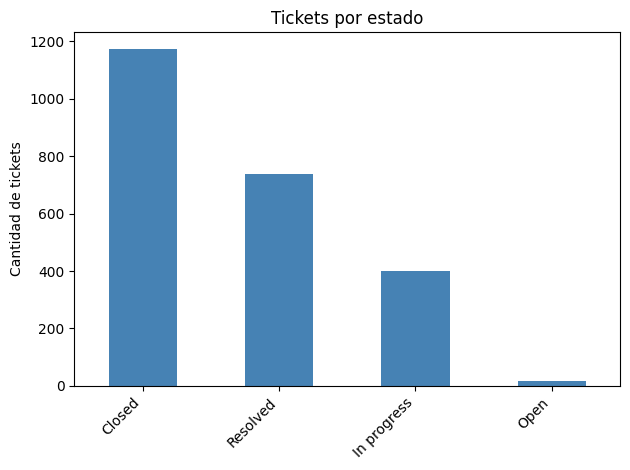

In [8]:
# 1. Tickets por estado
ax = df['status'].value_counts().plot(kind='bar', title='Tickets por estado', color='steelblue')
ax.set_ylabel('Cantidad de tickets'); ax.set_xlabel('')
plt.xticks(rotation=45, ha='right'); plt.tight_layout()
plt.savefig(IMG_DIR + '/01_tickets_por_estado.png', dpi=150); plt.show()

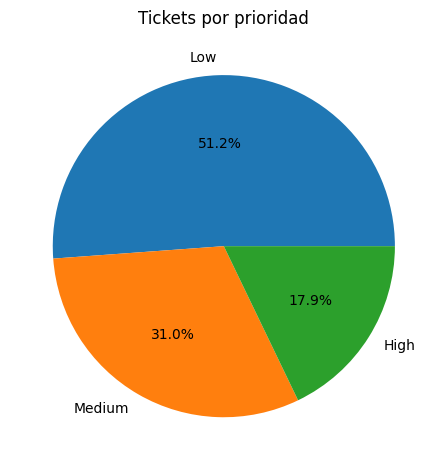

In [9]:
# 2. Tickets por prioridad
df['priority'].value_counts().plot(kind='pie', autopct='%1.1f%%', title='Tickets por prioridad')
plt.ylabel(''); plt.tight_layout()
plt.savefig(IMG_DIR + '/02_tickets_por_prioridad.png', dpi=150); plt.show()

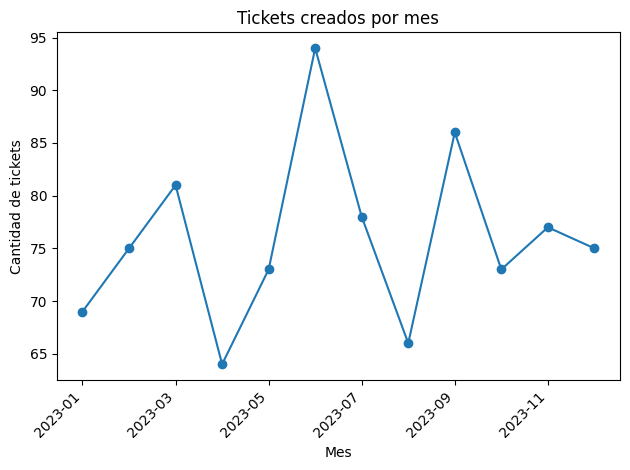

In [10]:
# 3. Evolución mensual
mensual = df.groupby('mes_creacion').size()
mensual = mensual[mensual.index != 'NaT']
ax = mensual.plot(kind='line', marker='o', title='Tickets creados por mes')
ax.set_ylabel('Cantidad de tickets'); ax.set_xlabel('Mes')
plt.xticks(rotation=45, ha='right'); plt.tight_layout()
plt.savefig(IMG_DIR + '/03_tickets_por_mes.png', dpi=150); plt.show()

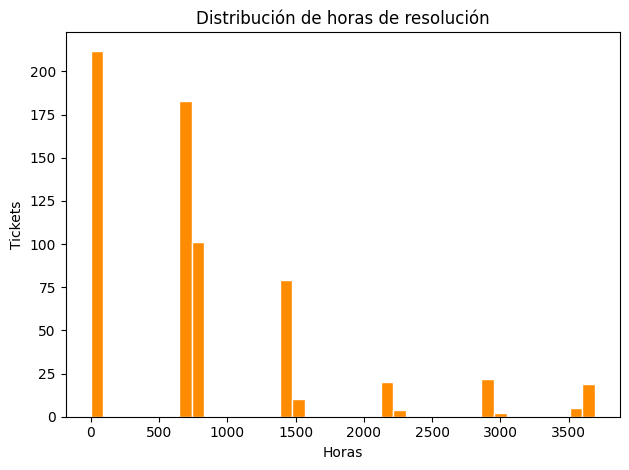

In [11]:
# 4. Distribución del tiempo de resolución (se recorta el 1% superior para legibilidad)
h = df['horas_resolucion'].dropna()
h = h[h <= h.quantile(0.99)]
plt.hist(h, bins=40, color='darkorange', edgecolor='white')
plt.title('Distribución de horas de resolución'); plt.xlabel('Horas'); plt.ylabel('Tickets')
plt.tight_layout(); plt.savefig(IMG_DIR + '/04_horas_resolucion.png', dpi=150); plt.show()

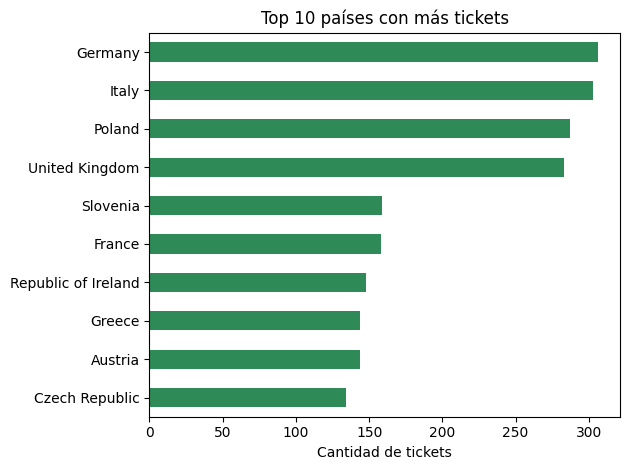

In [12]:
# 5. Top 10 países
top = df['country'].value_counts().head(10).sort_values()
ax = top.plot(kind='barh', title='Top 10 países con más tickets', color='seagreen')
ax.set_xlabel('Cantidad de tickets'); ax.set_ylabel('')
plt.tight_layout(); plt.savefig(IMG_DIR + '/05_top_paises.png', dpi=150); plt.show()

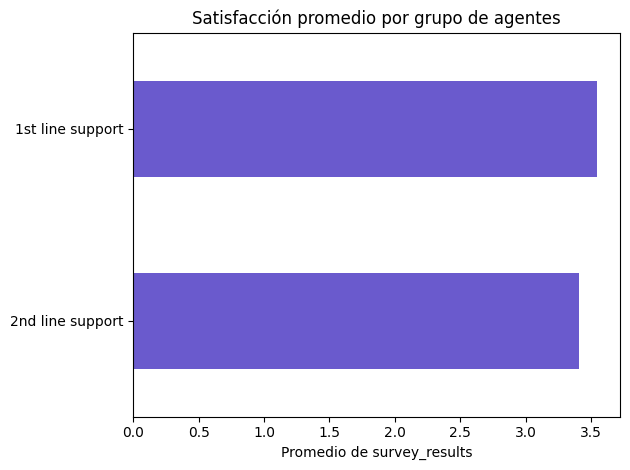

In [13]:
# 6. Satisfacción promedio por grupo de agentes
sat = df.groupby('agent_group')['survey_results'].mean().dropna().sort_values()
ax = sat.plot(kind='barh', title='Satisfacción promedio por grupo de agentes', color='slateblue')
ax.set_xlabel('Promedio de survey_results'); ax.set_ylabel('')
plt.tight_layout(); plt.savefig(IMG_DIR + '/06_satisfaccion_por_grupo.png', dpi=150); plt.show()

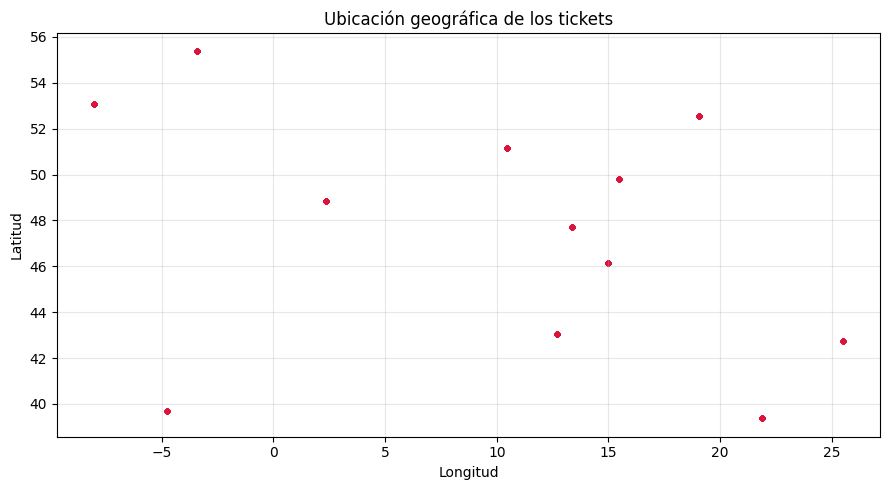

In [14]:
# 7. Ubicación de los tickets (latitud / longitud)
plt.figure(figsize=(9, 5))
plt.scatter(df['longitude'], df['latitude'], s=8, alpha=0.4, color='crimson')
plt.title('Ubicación geográfica de los tickets'); plt.xlabel('Longitud'); plt.ylabel('Latitud')
plt.grid(alpha=0.3); plt.tight_layout()
plt.savefig(IMG_DIR + '/07_mapa_coordenadas.png', dpi=150); plt.show()

## 5. Visualizaciones interactivas con Bokeh

In [15]:
from bokeh.plotting import figure, show
from bokeh.io import output_notebook
from bokeh.models import ColumnDataSource, HoverTool

output_notebook()

top10 = df['country'].value_counts().head(10)
src = ColumnDataSource(dict(pais=list(top10.index), tickets=list(top10.values)))

p = figure(x_range=list(top10.index), height=380, width=750,
           title='Top 10 países con más tickets', tools='pan,wheel_zoom,reset,save')
p.vbar(x='pais', top='tickets', width=0.8, source=src)
p.add_tools(HoverTool(tooltips=[('País', '@pais'), ('Tickets', '@tickets')]))
p.xaxis.major_label_orientation = 0.8
show(p)

In [16]:
serie = df.groupby('mes_creacion').size()
serie = serie[serie.index != 'NaT']
src2 = ColumnDataSource(dict(mes=list(serie.index), tickets=list(serie.values)))

p2 = figure(x_range=list(serie.index), height=380, width=750,
            title='Tickets por mes (interactivo)', tools='pan,wheel_zoom,reset,save')
p2.line(x='mes', y='tickets', source=src2, line_width=2)
p2.scatter(x='mes', y='tickets', source=src2, size=7)
p2.add_tools(HoverTool(tooltips=[('Mes', '@mes'), ('Tickets', '@tickets')]))
p2.xaxis.major_label_orientation = 0.8
show(p2)

## 6. Exploración interactiva con PyGWalker
Arrastra campos a los ejes para crear gráficos tipo Tableau y toma capturas para la Wiki.

In [17]:
import pygwalker as pyg
pyg.walk(df)

Exception in thread Thread-4 (_check_update):
Traceback (most recent call last):
  File "/usr/lib/python3.13/threading.py", line 1044, in _bootstrap_inner
    self.run()
    ~~~~~~~~^^
  File "/usr/lib/python3.13/threading.py", line 995, in run
    self._target(*self._args, **self._kwargs)
    ~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.13/dist-packages/pygwalker/services/check_update.py", line 104, in _check_update
    result = request_func(url)
  File "/usr/local/lib/python3.13/dist-packages/pygwalker/services/check_update.py", line 76, in _request_on_python
    with request.urlopen(url, timeout=30) as resp:
         ~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^
  File "/usr/lib/python3.13/urllib/request.py", line 189, in urlopen
    return opener.open(url, data, timeout)
           ~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^
  File "/usr/lib/python3.13/urllib/request.py", line 495, in open
    response = meth(req, response)
  File "/usr/lib/python3.13/urllib/request.py", line 60

Box(children=(HTML(value='\n<div id="ifr-pyg-00066155024cc6b4OpwJSy0gHYUEItBL" style="height: auto">\n    <hea…

## 7. Guardar el dataset final en Drive

In [18]:
FINAL_PATH = f'{DATA_DIR}/dssoporte_final.csv'
df.to_csv(FINAL_PATH, index=False)
print('Dataset final:', df.shape)
print('Guardado en:', FINAL_PATH)
print('Imágenes en:', IMG_DIR)
print(sorted(os.listdir(IMG_DIR)))


Dataset final: (2330, 26)
Guardado en: /content/drive/MyDrive/proyecto_soporte/data/dssoporte_final.csv
Imágenes en: /content/drive/MyDrive/proyecto_soporte/img
['01_tickets_por_estado.png', '02_tickets_por_prioridad.png', '03_tickets_por_mes.png', '04_horas_resolucion.png', '05_top_paises.png', '06_satisfaccion_por_grupo.png', '07_mapa_coordenadas.png']


Todo queda en `MyDrive/proyecto_soporte/`. Para GitHub, descarga desde Drive los archivos de `data/`, `sql/`, `db/` y las imágenes de `img/`.